In [1]:
import os
import math

import numpy as np
import keras
from keras import layers, ops
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

J_DEF = 1.0     # acoplamiento ferromagnético
H_DEF = 0.0     # campo externo
KB_DEF = 1.0    # unidades naturales

Consideremos un sistema $N$ de espínes situados en una red cuadrada de lado $L$, de tal forma que $L^2 = N$. Cada espín puede tomar los valores $s_i \in \{-1, +1\}$. La energía de una configuración s es

$$ E(s) = -J \sum_{\langle i,j \rangle} s_i s_j \; - \; h \sum_i s_i $$

Aquí usamos $J = 1$, $h =0$ y. $k_B = 1$. En equilibrio térmico a temperatura T, la probabilidad de cada configuración está dada por la distribución de Boltzmann:

$$ p_B(s) = \frac{e^{-E(s)/T}}{Z}, \qquad Z = \sum_{s} e^{-E(s)/T}, \qquad F_B = -T \ln Z $$

### Implementación - Secuencias de espines

Recorremos la red de espines $(\pm 1)$ y la convertimos a enteros (tokens), de forma que tengamos una transformación reversible entre ellas.

Así, un valor de espín $-1$, tiene un token de $0$, un espín $+1$. Cada secuencia de espín se desplaza, de modo que su posición inicial sea $2$, para que se identifique como el marcador de inicio de secuencia.

Las funciones se construyen de modo que puedan recibir multiples configuraciones a la vez. Lo cual es necesario para nuestra implementación.

In [2]:
# funciones para pasar de espines a tokens y desplazar
BOS = 2

def spin2tokens(s):
    """s en {-1,+1}, forma (M, N) o (M, L, L) -> tokens (M, N) en {0,1}"""
    s = np.asarray(s)
    return ((s.reshape(s.shape[0], -1) + 1) // 2).astype("int32")

def tokens2spin(t, L):
    """tokens (M, N) en {0,1} -> espines (M, L, L) en {-1,+1}. No modifica t."""
    return (2 * np.asarray(t) - 1).reshape(-1, L, L)

def entrada_desplazada(tokens):
    """tokens (M, N) -> (M, N): (BOS, s1, ..., s_{N-1})"""
    tokens = np.asarray(tokens, dtype="int32")
    bos = np.full((tokens.shape[0], 1), BOS, dtype="int32")
    return np.concatenate([bos, tokens[:, :-1]], axis=1)

def energia_ising_lote(s, L, J=J_DEF, h=H_DEF):
    """s (M, N) o (M, L, L) en {-1,+1} -> energías (M,). Frontera periódica."""
    r = np.asarray(s, dtype=np.int32).reshape(-1, L, L)
    vecinos = np.roll(r, -1, axis=1) + np.roll(r, -1, axis=2)   # abajo + derecha
    return (-J * np.sum(r * vecinos, axis=(1, 2))
            - h * np.sum(r, axis=(1, 2))).astype("float32")

### ejemplo

Suponemos por ejemplo 2 redes de espínes de tamaño $3 \times 3$. Veamos como funcionan las funciones

In [3]:
red_prueba= np.array([[[ 1, -1,  1], [-1, -1,  1], [ 1,  1, -1]],
               [ [ 1, 1,  1], [1, -1,  -1], [ -1,  1, -1]]])

print("redes de espines iniciales")
print(red_prueba)
print("=============================")
tokens_prueba =spin2tokens(red_prueba)
print("tokens de 2 redes: ")
print(tokens_prueba)
print("=============================")
espines = tokens2spin(tokens_prueba,3)
print("de regreso a espines")
print(espines)
print("=============================")
desplazada = entrada_desplazada(tokens_prueba)
print("secuencias desplazadas")
print(desplazada)


redes de espines iniciales
[[[ 1 -1  1]
  [-1 -1  1]
  [ 1  1 -1]]

 [[ 1  1  1]
  [ 1 -1 -1]
  [-1  1 -1]]]
tokens de 2 redes: 
[[1 0 1 0 0 1 1 1 0]
 [1 1 1 1 0 0 0 1 0]]
de regreso a espines
[[[ 1 -1  1]
  [-1 -1  1]
  [ 1  1 -1]]

 [[ 1  1  1]
  [ 1 -1 -1]
  [-1  1 -1]]]
secuencias desplazadas
[[2 1 0 1 0 0 1 1 1]
 [2 1 1 1 1 0 0 0 1]]


## Ariqutectura del Transformer

La red recibe la entrada desplazada, un arreglo de enteros de forma $(M, N)$, y devuelve logits de forma $(M, N, 2)$: en cada posición $i$, dos números cuyo softmax da $q_{\theta}(s_i = −1 | s_{<i})$ y $q_{\theta}(s_i = +1 | s_{<i})$. Usamos $d_{model} = 16, 2$ cabezas de atención, $d_{ff} = 32$ y 2 bloques.

La arquitectura del transformer se puede visualizar así

![Texto alternativo](arq_transformer.png)

### Embeddings


Un token es solo una etiqueta $(0, 1 \text{o} \, 2)$, sin noción de magnitud. El embedding de token ( layers.Embedding(3, d_model) )asigna a cada token un vector aprendible de dimensión $d_{model}$. Así la red puede aprender la representación más útil de “espín arriba”, “espín abajo” e “inicio”.

La atención, por sí sola, trata la secuencia como un conjunto: no sabe en qué posición está cada elemento. Pero en Ising la posición importa, porque determina quiénes son losvecinos. El embedding posicional ( EmbedPosicional ) suma a cada posición $i$ otro vector
aprendible $p_i.$ La entrada al primer bloque es entonces $x_i = e(token_i) + p_i$.


### Atención causal

Cada posición $i$ calcula tres proyecciones lineales de su vector: una consulta $q_i$ (query), una clave $k_i$ (key) y un valor $v_i$ (value). La salida en $i$ es un promedio ponderado de los
valores, con pesos dados por la similitud entre la consulta de $i$ y las claves de las demás posiciones:
$$ \text{Atención}(Q, K, V) = \text{softmax}\!\left( \frac{Q K^{\top}}
{\sqrt{d_k}} + \mathcal{M} \right) V, \qquad \mathcal{M}_{ij} = \begin{cases}
0 & j \le i \\ -\infty & j > i \end{cases} $$


La máscara causal ℳ es lo que hace que el modelo sea autorregresivo. En el código se implementa con keras.ops.where(j > i, -1e9, scores) : tras el softmax, el peso de toda posición futura es cero. Así, la salida en la posición i depende solo de las entradas $1,…, i$, que son $(BOS, s_1, …, s_{i−1})$. Esto garantiza que el logit $i$ solo usa los espines anteriores.

Con varias cabezas ( $n_{cabezas }= 2$), el vector de dimensión $d_{model}$ se divide en partes de dimensión $d_k = d_{model}/n_{cabezas}$, cada una con su propia atención. Así cada cabeza puede especializarse, por ejemplo en el vecino de la izquierda o en el de arriba. Al final, una proyección lineal $W_o$ recombina las cabezas.

Una capa Dense(2) final convierte el vector de cada posición en dos logits.

Aquí vamos a considerar 2 modelos, una implementación manual, donde construimos el transformer desde $0$ (manual) y ya directamente implementado con Keras.

In [4]:
# =============================================================
# Implementación "manual" - Funciones del lab08 
# =============================================================
class AtencionCausal(layers.Layer):

    def __init__(self, d_model, n_cabezas=2, **kwargs):
        super().__init__(**kwargs)
        assert d_model % n_cabezas == 0
        self.d_model = d_model
        self.n_cabezas = n_cabezas
        self.d_k = d_model // n_cabezas
        self.wq = layers.Dense(d_model, name="wq")
        self.wk = layers.Dense(d_model, name="wk")
        self.wv = layers.Dense(d_model, name="wv")
        self.wo = layers.Dense(d_model, name="wo")

    def _separar_cabezas(self, x):
        seq_len = keras.ops.shape(x)[1]
        x = keras.ops.reshape(x,(-1, seq_len, self.n_cabezas, self.d_k))
        return keras.ops.transpose(x,(0, 2, 1, 3))

    def call(self, x):
        seq_len = keras.ops.shape(x)[1]
        Q = self._separar_cabezas(self.wq(x))
        K = self._separar_cabezas(self.wk(x))
        V = self._separar_cabezas(self.wv(x))
        # Q K^T
        scores = keras.ops.matmul(Q,keras.ops.transpose(K, (0, 1, 3, 2)))
        scores = scores / math.sqrt(self.d_k)
        # ---------------------
        # máscara causal
        # ---------------------
        i = keras.ops.arange(seq_len)[:, None]
        j = keras.ops.arange(seq_len)[None, :]
        mascara = j > i
        scores = keras.ops.where(mascara,-1e9,scores)
        # softmax
        pesos = keras.ops.softmax(scores,axis=-1  )
        # A V
        salida = keras.ops.matmul(pesos,V)
        # juntar nuevamente las cabezas
        salida = keras.ops.transpose(salida,(0, 2, 1, 3))
        salida = keras.ops.reshape(salida,(-1, seq_len, self.d_model))
        salida = self.wo(salida)
        return salida, pesos

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"d_model": self.d_model, "n_cabezas": self.n_cabezas})
        return cfg


class EmbedPosicional(layers.Layer):

    def __init__(self, seq_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.seq_len = seq_len
        self.d_model = d_model
        self.pos_emb = layers.Embedding(seq_len,d_model)

    def call(self, x):
        seq_len = keras.ops.shape(x)[1]
        posiciones = keras.ops.arange(seq_len)
        return x + self.pos_emb(posiciones)

class BloqueTransformer(layers.Layer):

    def __init__(self,d_model,n_cabezas,d_ff,**kwargs):
        super().__init__(**kwargs)
        self.d_model   = d_model
        self.n_cabezas = n_cabezas
        self.d_ff      = d_ff
        self.atencion  = AtencionCausal(d_model, n_cabezas)
        self.norm1     = layers.LayerNormalization()
        self.ffn       = keras.Sequential([
            layers.Dense(d_ff, activation="relu"),
            layers.Dense(d_model),
        ])
        self.norm2     = layers.LayerNormalization()


    def call(self, x):
        atn_out, pesos = self.atencion(x)
        # residual 1
        x = self.norm1(x + atn_out)

        # FFN + residual 2
        x = self.norm2(x + self.ffn(x))
        return x, pesos

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"d_model": self.d_model,
                    "n_cabezas": self.n_cabezas,
                    "d_ff": self.d_ff})
        return cfg

# =============================================================
# Implementación "general" (API Keras: layers.MultiHeadAttention)
# =============================================================
class BloqueTransformerGeneral(layers.Layer):
    def __init__(self, d_model, n_cabezas, d_ff, **kwargs):
        super().__init__(**kwargs)
        self.d_model   = d_model
        self.n_cabezas = n_cabezas
        self.d_ff      = d_ff
        self.atencion = layers.MultiHeadAttention(
            num_heads      = n_cabezas,
            key_dim        = d_model // n_cabezas,
            value_dim      = d_model // n_cabezas,
            use_bias       = True,
            dropout        = 0.0,     # sin dropout
            name           = "mha",
        )
        self.norm1 = layers.LayerNormalization()
        self.ffn   = keras.Sequential([
            layers.Dense(d_ff, activation="relu"),
            layers.Dense(d_model),
        ])
        self.norm2 = layers.LayerNormalization()

    def call(self, x):
        atn_out, pesos = self.atencion(
            x, x, use_causal_mask=True, return_attention_scores=True,
        )
        x = self.norm1(x + atn_out)
        x = self.norm2(x + self.ffn(x))
        return x, pesos

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"d_model": self.d_model,
                    "n_cabezas": self.n_cabezas,
                    "d_ff": self.d_ff})
        return cfg


# =============================================================
# Elegir si usamos la máscara construida a mano o la de Keras
# =============================================================
BLOQUES = {
    "manual": BloqueTransformer,          # atención a mano
    "keras":  BloqueTransformerGeneral,   # MultiHeadAttention
}

In [5]:
def construir_transformer(N, vocab_size=3, d_model=16, n_cabezas=2,
                          d_ff=32, n_bloques=2, atencion='manual'):
    Bloque = BLOQUES[atencion]
    entrada = keras.Input(shape=(N,), dtype="int32")          # (BOS, s1..s_{N-1})
    x = layers.Embedding(vocab_size, d_model, name="token_embedding")(entrada)
    x = EmbedPosicional(N, d_model, name="pos_embedding")(x)

    for b in range(n_bloques):
        x, _ = Bloque(d_model, n_cabezas, d_ff, name=f"bloque_{b}")(x)
    logits = layers.Dense(2, name="logits")(x)                # (M, N, 2)
    return keras.Model(entrada, logits, name=f"transformer_ising_{atencion}")

### Prueba de causalidad

Si tenemos una secuencia de espínes, cambiar el espínen la posición $k$, solo hace que cambien las predicciones posteriores (la máscara causal hace que solo se vean espines anteriores).

In [6]:
# ejemplo: red 4x4 de 16 espins
L, N = 4, 16


def test_causalidad(atencion="manual", k=7, seed=0):
    keras.utils.set_random_seed(seed)
    modelo = construir_transformer(N, atencion=atencion)

    rng = np.random.default_rng(seed)
    t   = rng.integers(0, 2, (1, N))
    t2  = t.copy()
    t2[0, k] = 1 - t2[0, k]

    z1 = keras.ops.convert_to_numpy(modelo(entrada_desplazada(t),  training=False))
    z2 = keras.ops.convert_to_numpy(modelo(entrada_desplazada(t2), training=False))
    diff = np.abs(z1 - z2).max(axis=-1)[0]   # (N,)

    # Patrón esperado: ceros hasta k inclusive, positivos desde k+1
    sin_cambio = np.all(diff[:k+1] == 0)
    con_cambio = np.all(diff[k+1:] > 0)

    patron = "".join("0" if d == 0 else "x" for d in diff)
    print(f"atencion={atencion:6s} | k={k:2d} | patrón: {patron}")
    print(f"  diff[0..{k}]     == 0  →  {'OK' if sin_cambio else 'FALLA'}")
    print(f"  diff[{k+1}..{N-1}] >  0  →  {'OK' if con_cambio else 'FALLA'}")
    print(f"  resultado: {'✔ causal' if (sin_cambio and con_cambio) else '✘ rompe causalidad'}")
    print("-" * 60)

    return diff, sin_cambio and con_cambio


# --- ambas implementaciones, caso central ---
_ = test_causalidad("manual", k=7)
_ = test_causalidad("keras",  k=7)

# --- casos borde ---
_ = test_causalidad("manual", k=0)      # patrón 0xxxxxxxxxxxxxxx
_ = test_causalidad("manual", k=N-1)    # patrón 0000000000000000

atencion=manual | k= 7 | patrón: 00000000xxxxxxxx
  diff[0..7]     == 0  →  OK
  diff[8..15] >  0  →  OK
  resultado: ✔ causal
------------------------------------------------------------
atencion=keras  | k= 7 | patrón: 00000000xxxxxxxx
  diff[0..7]     == 0  →  OK
  diff[8..15] >  0  →  OK
  resultado: ✔ causal
------------------------------------------------------------
atencion=manual | k= 0 | patrón: 0xxxxxxxxxxxxxxx
  diff[0..0]     == 0  →  OK
  diff[1..15] >  0  →  OK
  resultado: ✔ causal
------------------------------------------------------------
atencion=manual | k=15 | patrón: 0000000000000000
  diff[0..15]     == 0  →  OK
  diff[16..15] >  0  →  OK
  resultado: ✔ causal
------------------------------------------------------------


### Prueba de normalización

Con $L = 4$ tenemos $2^{16} = 65536$ configuraciones. Si sumamos todas las probabilidades condicionales (que son outputs de un softmax), obtenemos $1$. Es decir, la función $q_{\theta}$ está normalizada por construcción.

Aquí dada nuestra configuración, una sola ejecución del modelo nos da los $N$ condicionales a la vez dado el desplazamiento de la secuencia y la máscara causal. Aplicamos log_softmax y, en cada posición, elegimos con one_hot el logaritmo del espín que realmente ocurrió. Sumar sobre las posiciones da $ℓ(s) = ln q_{\theta}(s)$.

In [7]:
# logaritmo de las probabilidades condicionales
def log_prob(modelo, tokens):
    """tokens (M, N) en {0,1} -> ln q(s) de forma (M,)"""
    tokens = np.asarray(tokens, dtype="int32")
    logits = modelo(entrada_desplazada(tokens), training=False)               # (M, N, 2)
    logp = keras.ops.log_softmax(logits, axis=-1)                             # (M, N, 2)
    seleccion = keras.ops.one_hot(tokens, 2)                                  # (M, N, 2)
    return keras.ops.sum(logp * seleccion, axis=(1, 2))                       # (M,)

In [8]:
def test_normalizacion(atencion="manual", L_red=4, seed=0):
    N = L_red * L_red
    keras.utils.set_random_seed(seed)
    modelo = construir_transformer(N, atencion=atencion)

    # todas las configuraciones: (2^N, N) en {0,1}
    todas = ((np.arange(2**N)[:, None] >> np.arange(N)[::-1]) & 1).astype("int32")

    lq      = keras.ops.convert_to_numpy(log_prob(modelo, todas))
    q       = np.exp(lq)
    suma    = q.sum()
    error   = abs(suma - 1.0)
    ok      = error < 1e-5          # float32 → ~1e-7 típico

    print(f"atencion={atencion:6s} | L={L_red} | N={N:2d} | 2^N={2**N:6d}")
    print(f"  Σ q_θ(s)  = {suma:.8f}")
    print(f"  error     = {error:.2e}")
    print(f"  resultado = {'✔ normalizada' if ok else '✘ no normalizada'}")
    print("-" * 60)
    return suma, ok


# --- prueba rápida (N = 9, 512 configs) ---
_ = test_normalizacion("manual", L_red=3)
_ = test_normalizacion("keras",  L_red=3)

# --- prueba completa (N = 16, 65536 configs) ---
_ = test_normalizacion("manual", L_red=4)
_ = test_normalizacion("keras",  L_red=4)

atencion=manual | L=3 | N= 9 | 2^N=   512
  Σ q_θ(s)  = 1.00000012
  error     = 1.19e-07
  resultado = ✔ normalizada
------------------------------------------------------------
atencion=keras  | L=3 | N= 9 | 2^N=   512
  Σ q_θ(s)  = 1.00000000
  error     = 0.00e+00
  resultado = ✔ normalizada
------------------------------------------------------------
atencion=manual | L=4 | N=16 | 2^N= 65536
  Σ q_θ(s)  = 1.00000012
  error     = 1.19e-07
  resultado = ✔ normalizada
------------------------------------------------------------
atencion=keras  | L=4 | N=16 | 2^N= 65536
  Σ q_θ(s)  = 1.00000000
  error     = 0.00e+00
  resultado = ✔ normalizada
------------------------------------------------------------


## Muestreo Secuencial

La distirbución de probabilidad que queremos construir con el transformer autoregresivo es un modelo parámetrico $q_{\theta}(s)$, siendo $s$ una configuración de espínes y $\theta$ el conjunto de parámetros (incluye los embeddings, bloques de atención y capa de salida). Dada la máscara causal, la distribución de probabilidad se puede escribir como 


$$ q_{\theta}(\mathbf{s}) = \prod _{i=1} ^{N} q_{\theta} (s_i |s_1, ..., s_{i-1} )$$


Definimos la función muestrear que permite justamente generar configuraciones espín por espín. Generamos $M$ configuraciones en paralelo, con $N$ evaluaciones por lote. Las muestras son independientes entre sí y no correlación ni termalización como en Monte Carlo. 

La función se estructura de la siguiente forma: 

1. Inicializar la secuencia con el BOS (las demás posiciones no importan por la máscara causal).

2. En la iteración $i$, se evalúa el modelo de atención, se aplica la función softmax al logit $i$. $s_i = 1$  tiene asociada una probabilidad $q_{\theta} (s_i = +1 | s_{< i})$.

3. El espín generado se escribe en la posición $i+1$ de la entrada,  para que condicione el siguiente paso. 

In [9]:
def muestrear(modelo, M, N, semilla=None):
    """Genera M configuraciones s ~ q_theta. Devuelve tokens (M, N) en {0,1}."""
    rng = np.random.default_rng(semilla)
    entrada = np.full((M, N), BOS, dtype="int32")   
    tokens  = np.zeros((M, N), dtype="int32")

    for i in range(N):
        logits = modelo(entrada, training=False)             # (M, N, 2)
        p = keras.ops.convert_to_numpy(
                keras.ops.softmax(logits[:, i, :], axis=-1))  # (M, 2)
        s_i = (rng.random(M) < p[:, 1]).astype("int32")     # 1 con prob. q(s_i=+1|s<i)
        tokens[:, i] = s_i
        if i + 1 < N:
            entrada[:, i + 1] = s_i                          # alimenta el siguiente paso
    return tokens

### Prueba de muestreo

Con $L = 3$ tenemos $2^9 = 512$ configuraciones. Comparamos $q_{exacta}(s) = e^{l(s)}$ evaluada con 'log_prob' sobre todas las configuraciones y, $q_{emp}(s)$ como la frecuencia de cada configuración en $M = 50000$ muestras. 


In [10]:
def test_muestreo(atencion="manual", L_red=3, M=50_000, seed=0):
    """Compara q_empírica (de muestrear) con q_exacta (de log_prob)."""
    N = L_red * L_red
    keras.utils.set_random_seed(seed)
    modelo = construir_transformer(N, atencion=atencion)

    # --- q exacta sobre las 2^N configuraciones ---
    todas = ((np.arange(2**N)[:, None] >> np.arange(N)[::-1]) & 1).astype("int32")
    q_exacta = np.exp(keras.ops.convert_to_numpy(log_prob(modelo, todas)))

    # --- q empírica a partir de M muestras ---
    muestras = muestrear(modelo, M, N, semilla=seed)
    indices  = muestras @ (2 ** np.arange(N)[::-1])
    q_emp    = np.bincount(indices, minlength=2**N) / M

    # --- errores ---
    err_max  = np.abs(q_emp - q_exacta).max()
    err_prom = np.abs(q_emp - q_exacta).mean()
    # Error estadístico esperado: ~ 1/sqrt(M) para conteos Poisson
    err_esperado = 1.0 / np.sqrt(M)

    print(f"atencion={atencion:6s} | L={L_red} | M={M} | 2^N={2**N}")
    print(f"  Σ q_exacta          = {q_exacta.sum():.8f}")
    print(f"  Σ q_empírica        = {q_emp.sum():.8f}")
    print(f"  max |q_emp - q_ex | = {err_max:.6f}")
    print(f"  mean|q_emp - q_ex | = {err_prom:.6f}")
    print(f"  error esperado 1/√M = {err_esperado:.6f}")
    # Regla práctica: err_max debe ser O(3·err_esperado), no O(1)
    ok = err_max < 5 * err_esperado
    print(f"  resultado           = {'✔ muestreo consistente' if ok else '✘ inconsistente'}")
    print("-" * 60)
    return err_max, err_esperado


# --- pruebas ---
_ = test_muestreo("manual", L_red=3, M=50_000, seed=0)
_ = test_muestreo("keras",  L_red=3, M=50_000, seed=0)

atencion=manual | L=3 | M=50000 | 2^N=512
  Σ q_exacta          = 1.00000012
  Σ q_empírica        = 1.00000000
  max |q_emp - q_ex | = 0.001673
  mean|q_emp - q_ex | = 0.000078
  error esperado 1/√M = 0.004472
  resultado           = ✔ muestreo consistente
------------------------------------------------------------
atencion=keras  | L=3 | M=50000 | 2^N=512
  Σ q_exacta          = 1.00000000
  Σ q_empírica        = 1.00000000
  max |q_emp - q_ex | = 0.001299
  mean|q_emp - q_ex | = 0.000097
  error esperado 1/√M = 0.004472
  resultado           = ✔ muestreo consistente
------------------------------------------------------------


Ambas implementaciones tienen un error máximo que está por debajo de la desviación estándar $1/\sqrt{M} \approx 0.045$. El muestreo secuencial reproduce exactamente la distribución que asigna 'log_prob'.

 Las tres pruebas realizadas (causalidad, normalización y muestreo) garantizan que $q_\theta$ es una distribución bien definida y normalizada, de la que sabemos calcular $\ln q_\theta(s)$ y muestrear exactamente. Es justo lo que necesita el método variacional.

## Entrenamiento Variacional 

Para cuantificar la diferencia entre la distribución parámetrica $q_{\theta}(s)$ y la distribución de Boltzmman, usamos la divergencia de Kullback–Leibler:

$$ D_{KL}(q_{\theta} | p_B ) = \sum_{\mathbf{s}} q_{\theta} (\mathbf{s}) \ln \frac{q_{\theta} (\mathbf{s}) }{P_B (\mathbf{s}) } $$

Dada una distribución arbritraria, tenemos que

$$ D_{KL}(q_{\theta} | p_B ) = \beta F[q] - \beta F_B,  $$

donde $F[q] = U[q] - T\,S[q] = \sum_s q(s)\big[E(s) + T \ln q(s)\big] = \mathbb{E}_{s\sim q}\big[E(s) + T\ln q(s)\big]$  y $F_B = - \ln Z/ \beta$.

Usando $\ln p_B(s) = -E(s)/T - \ln Z$ se obtiene

$$ F[q] = F_B + T\, D_{KL}(q \,\|\, p_B) \;\ge\; F_B , $$

con igualdad solo si $q = p_B$. Minimizar $F[q]$ es equivalente a minimizar la divergencia KL $D_{KL}(q\|p_B)$. Notemos que nunca hace falta calcular $Z$, basta con muestrear de $q_\theta$ y evaluar $E(s)$ y $\ln q_\theta(s)$.


### Estimador del gradiente

En cada iteración generamos un lote de M configuraciones independientes con los parámetros actuales $\mathbf{s}^{(1)}, ..., \mathbf{s}^{(M)} \sim q_{\theta}$.

Para cada configuracón calculamos dos cantidades: $E_, = E(\mathbf{s}^{m})$, $l_m = \ln q_{\theta} (\mathbf{s}^{m})$. 


Sea $f(s) = E(s) + T \ln q_\theta(s)$. Derivando,

$$ \nabla_\theta F = \mathbb{E}_{q}\big[f(s)\,\nabla_\theta \ln q_\theta(s)\big] + T\,\mathbb{E}_{q}\big[\nabla_\theta \ln q_\theta(s)\big]. $$

El segundo término es cero porque $\mathbb{E}_q[\nabla \ln q] = \sum_s \nabla q = \nabla 1 = 0$. Por la misma razón podemos restar cualquier constante $b$ (*baseline*) sin sesgar el gradiente:

$$ \nabla_\theta F \approx \frac{1}{M}\sum_{k=1}^{M} \big(f(s^{(k)}) - b\big)\,\nabla_\theta \ln q_\theta(s^{(k)}), \qquad b = \bar f = \frac{1}{M}\sum_k f(s^{(k)}). $$

Restar el promedio reduce mucho la varianza: solo las configuraciones con $f$ mejor que el promedio aumentan su probabilidad.


### Implementación (paso_entrenamiento)

1. **Muestras fuera del `GradientTape`.** El muestreo es discreto y no diferenciable; la dependencia en $\theta$ entra solo a través de $\nabla \ln q_\theta$.
2. **Reevaluar $\ell = \ln q_\theta(s)$ dentro del tape**, ahora sí con gradiente, y formar $f = E + T\ell$.
3. **`stop_gradient` sobre $f$**: $f$ actúa como un peso (una "recompensa"), no se deriva. La pérdida auxiliar $\mathcal{L}_{aux} = \langle (f - \bar f)\,\ell \rangle$ está construida para que su gradiente sea exactamente el estimador de arriba; su valor no tiene significado físico.
4. Se aplica el paso de Adam.
5. Se registran $F/N$, $U/N = \langle E\rangle/N$ y $S/N = -\langle \ell \rangle/N$, estimados con el mismo lote (por eso fluctúan de una iteración a otra).

Usar como baseline el promedio del mismo lote introduce un sesgo de orden $1/M$, despreciable con $M = 256$.


Con $L = 3$, la función partición puede calcularse facilmente enumerando las $512$ configuraciones posibles. Esto nos permite comparar el modelo parámetrico con el modelo exacto.

In [11]:
def paso_entrenamiento(modelo, optimizador, M, L, T, J=J_DEF, h=H_DEF, baseline=False, seed=None):
    N = L * L
    # 1) muestras fijas, sin gradiente
    tokens = muestrear(modelo, M, N, semilla=seed)
    E = energia_ising_lote(tokens2spin(tokens, L), L, J, h)       # (M,) numpy

    # 2) reevaluar ln q con gradiente
    with tf.GradientTape() as tape:
        ell = log_prob(modelo, tokens)                            # (M,) tensor
        f = tf.constant(E) + T * ell
        f_sg = tf.stop_gradient(f)
        if baseline:
            f_sg = f_sg - tf.reduce_mean(f_sg)                    # reducción de varianza
        L_aux = tf.reduce_mean(f_sg * ell)

    grads = tape.gradient(L_aux, modelo.trainable_variables)
    pares = [(g, v) for g, v in zip(grads, modelo.trainable_variables) if g is not None]
    optimizador.apply_gradients(pares)

    # 3) cantidades para registrar (por espín)
    ell_np = ell.numpy()
    U = E.mean()
    S = -ell_np.mean()
    F = U - T * S
    return F / N, U / N, S / N

### Entrenamiento con $L = 3, T = 2$

$L = 3$ ($N = 9$), $T = 2.0$ (por debajo de $T_c = 2/\ln(1+\sqrt2) \approx 2.269$ de la red infinita, es decir, en la fase ordenada), $M = 256$ muestras por iteración, $K = 300$ iteraciones, Adam con tasa $10^{-3}$ y baseline activado. En cada iteración se usa una semilla de muestreo distinta, y ambas implementaciones parten de la misma semilla global.

In [12]:
L,T = 3, 2.0
N    = L * L
SEED = 42
M_LOTE = 256
K_ITERS = 300

def entrenar_basico(atencion="manual", K=K_ITERS, M=M_LOTE, seed=SEED,
                    baseline=True, verbose_every=25):
    keras.utils.set_random_seed(seed)
    modelo = construir_transformer(N, atencion=atencion)
    optimizador = keras.optimizers.Adam(learning_rate=1e-3)

    historial = []
    for k in range(K):
        F, U, S = paso_entrenamiento(
            modelo, optimizador, M=M, L=L, T=T,
            baseline=baseline, seed=seed + k,   # semilla distinta por iter
        )
        historial.append((F, U, S))
        if verbose_every and k % verbose_every == 0:
            print(f"iter {k:4d}  F/N={F:+.4f}  U/N={U:+.4f}  S/N={S:.4f}")

    return modelo, np.array(historial)


# --- referencia exacta (Boltzmann) para L=3, T=2 ---
todas = ((np.arange(2**N)[:, None] >> np.arange(N)[::-1]) & 1).astype("int32")
E_todas = energia_ising_lote(tokens2spin(todas, L), L).astype(np.float64)
lnZ = np.log(np.exp(-(E_todas - E_todas.min()) / T).sum()) - E_todas.min() / T
F_B_N = -T * lnZ / N
print(f"F_B/N exacto (L={L}, T={T}) = {F_B_N:+.4f}")
print("-" * 60)

# --- entrenar ambas implementaciones con la misma semilla ---
print("=== atencion=manual ===")
modelo_manual, hist_manual = entrenar_basico("manual", baseline=True)

print("=== atencion=keras ===")
modelo_keras, hist_keras = entrenar_basico("keras", baseline=True)

# --- resumen final con promedio de las últimas 50 iteraciones ---
for nombre, h in [("manual", hist_manual), ("keras", hist_keras)]:
    F_final = h[-50:, 0].mean()
    print(f"{nombre:6s} | F/N últimas 50 iters = {F_final:+.4f} "
          f"(|Δ| vs exacto = {abs(F_final - F_B_N):.4f})")

F_B/N exacto (L=3, T=2.0) = -2.2056
------------------------------------------------------------
=== atencion=manual ===
iter    0  F/N=-1.4332  U/N=-0.2448  S/N=0.5942
iter   25  F/N=-2.0368  U/N=-1.7465  S/N=0.1451
iter   50  F/N=-2.0370  U/N=-1.8177  S/N=0.1096
iter   75  F/N=-2.0349  U/N=-1.8125  S/N=0.1112
iter  100  F/N=-2.0501  U/N=-1.8038  S/N=0.1232
iter  125  F/N=-2.1974  U/N=-1.8438  S/N=0.1768
iter  150  F/N=-2.1998  U/N=-1.8003  S/N=0.1997
iter  175  F/N=-2.1992  U/N=-1.8021  S/N=0.1986
iter  200  F/N=-2.1995  U/N=-1.7552  S/N=0.2222
iter  225  F/N=-2.1906  U/N=-1.7361  S/N=0.2272
iter  250  F/N=-2.1964  U/N=-1.8333  S/N=0.1816
iter  275  F/N=-2.2002  U/N=-1.8021  S/N=0.1990
=== atencion=keras ===
iter    0  F/N=-1.1402  U/N=-0.0278  S/N=0.5562
iter   25  F/N=-2.0373  U/N=-1.9080  S/N=0.0646
iter   50  F/N=-2.0433  U/N=-1.8247  S/N=0.1093
iter   75  F/N=-2.0401  U/N=-1.8507  S/N=0.0947
iter  100  F/N=-2.0405  U/N=-1.8368  S/N=0.1019
iter  125  F/N=-2.0457  U/N=-1.8507  S/N

## Verificación exacta

In [17]:
def comparacion_exacta(modelo, L, T, nombre="modelo"):
    N = L * L
    todas = ((np.arange(2**N)[:, None] >> np.arange(N)[::-1]) & 1).astype("int32")
    E = energia_ising_lote(tokens2spin(todas, L), L).astype(np.float64)

    # --- Boltzmann exacto (con desplazamiento de E.min() por estabilidad) ---
    lnZ   = np.log(np.sum(np.exp(-(E - E.min()) / T))) - E.min() / T
    F_B   = -T * lnZ
    log_p_B = -E / T - lnZ                      # log p_B DIRECTAMENTE
    p_B     = np.exp(log_p_B)                   # solo para reportar

    # --- modelo ---
    lq = keras.ops.convert_to_numpy(log_prob(modelo, todas)).astype(np.float64)
    q  = np.exp(lq)

    # --- observables exactos de q_θ ---
    U_q = np.sum(q * E)
    S_q = -np.sum(q * lq)
    F_q = U_q - T * S_q                       # ≡ Σ q (E + T ln q)

    # --- KL usando log_p_B directo (evita underflow de p_B) ---
    D_KL = np.sum(q * (lq - log_p_B))

    # --- residuos / cotas ---
    residuo_identidad = (F_q - F_B) / T - D_KL
    cota_variacional  = F_q - F_B               # debe ser ≥ 0
    normalizacion     = abs(q.sum() - 1.0)

    print(f"===== {nombre} (L={L}, T={T}) =====")
    print(f"normalización Σq           = {q.sum():.8f}   (|Σq-1|={normalizacion:.2e})")
    print(f"F_B/N exacto               = {F_B / N:+.5f}")
    print(f"U[q]/N   enumeración       = {U_q / N:+.5f}")
    print(f"S[q]/N   enumeración       = {S_q / N:+.5f}")
    print(f"F[q]/N   enumeración       = {F_q / N:+.5f}")
    print(f"D_KL                       = {D_KL:.6f}")
    print(f"(F_q - F_B)/T              = {(F_q - F_B) / T:.6f}   (debe = D_KL)")
    print(f"residuo identidad          = {residuo_identidad:.2e}   (debe ≈ 0)")
    print(f"cota variacional F_q-F_B   = {cota_variacional:+.2e}   (debe ≥ 0)")
    ground = np.isclose(E, E.min())
    print(f"q    en estados fundam.    = {q[ground].round(4)}")
    print(f"p_B  en estados fundam.    = {p_B[ground].round(4)}")
    return q, p_B, E, F_q, D_KL


q_m, p_B, E, F_m, D_m = comparacion_exacta(modelo_manual, L=3, T=2.0, nombre="manual")
q_k, _,   _, F_k, D_k = comparacion_exacta(modelo_keras,  L=3, T=2.0, nombre="keras")

print("\n===== resumen manual vs keras =====")
N_test = 9
print(f"manual | F[q]/N = {F_m / N_test:+.5f} | D_KL = {D_m:.6f}")
print(f"keras  | F[q]/N = {F_k / N_test:+.5f} | D_KL = {D_k:.6f}")
print(f"diferencia |ΔF/N| = {abs(F_m - F_k) / N_test:.5f} | |ΔD_KL| = {abs(D_m - D_k):.6f}")

===== manual (L=3, T=2.0) =====
normalización Σq           = 0.99999996   (|Σq-1|=3.69e-08)
F_B/N exacto               = -2.20559
U[q]/N   enumeración       = -1.80614
S[q]/N   enumeración       = +0.19649
F[q]/N   enumeración       = -2.19912
D_KL                       = 0.029127
(F_q - F_B)/T              = 0.029127   (debe = D_KL)
residuo identidad          = 3.66e-07   (debe ≈ 0)
cota variacional F_q-F_B   = +5.83e-02   (debe ≥ 0)
q    en estados fundam.    = [0.4135 0.4069]
p_B  en estados fundam.    = [0.3965 0.3965]
===== keras (L=3, T=2.0) =====
normalización Σq           = 1.00000001   (|Σq-1|=1.21e-08)
F_B/N exacto               = -2.20559
U[q]/N   enumeración       = -1.84745
S[q]/N   enumeración       = +0.09807
F[q]/N   enumeración       = -2.04359
D_KL                       = 0.728977
(F_q - F_B)/T              = 0.728976   (debe = D_KL)
residuo identidad          = -1.20e-07   (debe ≈ 0)
cota variacional F_q-F_B   = +1.46e+00   (debe ≥ 0)
q    en estados fundam.    = [0.

### Resultados:

- **manual:** $D_{KL} = 0.029$ y $F[q]/N = -2.1991$, frente a $-2.2056$ exacto. Pone $q \approx 0.41$ en cada estado fundamental, frente a $p_B = 0.397$: los dos modos aparecen, aunque ligeramente sobrepoblados. Por eso $U[q]/N = -1.806$ queda por debajo del exacto ($-1.768$) y $S[q]/N = 0.196$ por debajo del exacto ($S_B/N = (U_B - F_B)/(NT) = 0.219$). Es el comportamiento típico de la KL inversa: $q$ resulta un poco más concentrada (más ordenada) que $p_B$.
- **keras:** $D_{KL} = 0.733 \approx \ln 2 + 0.04$, con $q = [0.83,\ 0.00]$ en los estados fundamentales. Esto confirma el colapso de modo: casi toda la masa del segundo estado fundamental se fue al primero. El excedente $\approx 0.04$ sobre $\ln 2$ es el error de ajuste dentro del modo, comparable al $0.029$ del modelo manual.

Este cálculo exacto solo es posible porque $N$ es pequeño. Para redes grandes solo tenemos la estimación por muestreo de $F[q]$, que sigue siendo una cota superior de $F_B$, pero ya no conocemos $D_{KL}$ porque no conocemos $Z$.

### Evaluación Modelo Entrenado

Ahora queremos generar un lote independiente de evaluación para estime la energía libre por espín, la energía media por espín y lamagnetización absoluta.

Para esto, construimos la función `enumeración(L, T)`, que nos da todas las configuraciones, y las cantidades termodinámicas exactas: $F/N$, $U/N$ y $\langle|m| \rangle$. 

La función `evaluar(modelo, L, T)`: genera $10\,000$ configuraciones **nuevas** (en bloques de $2\,000$ por memoria, con semillas distintas a las del entrenamiento) y estima

$$ \frac{F}{N} \approx \Big\langle \frac{E + T\ln q_\theta}{N} \Big\rangle, \qquad \frac{U}{N} \approx \Big\langle \frac{E}{N} \Big\rangle, \qquad \langle |m| \rangle . $$



In [18]:
def enumeracion(L, T):
    """Enumera todas las configuraciones y calcula observables exactos."""
    N = L * L
    todas = ((np.arange(2**N)[:, None] >> np.arange(N)[::-1]) & 1).astype("int32")
    s = tokens2spin(todas, L)
    E = energia_ising_lote(s, L).astype(np.float64)
    absm = np.abs(s.mean(axis=(1, 2)))
    lnZ = np.log(np.sum(np.exp(-(E - E.min()) / T))) - E.min() / T
    p_B = np.exp(-E / T - lnZ)
    exacto = {
        "F/N":   -T * lnZ / N,
        "U/N":   np.sum(p_B * E) / N,
        "<|m|>": np.sum(p_B * absm),
    }
    return todas, E, p_B, exacto


def evaluar(modelo, L, T, M=10_000, bloque=2_000, seed=0):
    """Estima F/N, U/N, <|m|> con lotes independientes.

    Barras de error: σ/√M sobre M muestras agrupadas en bloque.
    """
    N = L * L
    E_list, ell_list, m_list = [], [], []
    for b in range(M // bloque):
        tok = muestrear(modelo, bloque, N, semilla=seed + b)
        s = tokens2spin(tok, L)
        E_list.append(energia_ising_lote(s, L))
        ell_list.append(keras.ops.convert_to_numpy(log_prob(modelo, tok)))
        m_list.append(np.abs(s.mean(axis=(1, 2))))
    E_all = np.concatenate(E_list)
    ell   = np.concatenate(ell_list)
    m_all = np.concatenate(m_list)

    f = (E_all + T * ell) / N
    est = lambda x: (x.mean(), x.std() / np.sqrt(len(x)))
    return {
        "F/N":   est(f),
        "U/N":   est(E_all / N),
        "<|m|>": est(m_all),
    }


def tabla(modelo, L, T, nombre="modelo"):
    """Tabla comparativa: estimación del modelo vs exacto."""
    _, _, _, exacto = enumeracion(L, T)
    est = evaluar(modelo, L, T)
    print(f"===== {nombre} (L={L}, T={T}) =====")
    print(f"{'':8s}{'modelo':>22s}{'exacto':>12s}")
    for k in exacto:
        v, e = est[k]
        print(f"{k:8s}{v:>14.4f} ± {e:.4f}{exacto[k]:>12.4f}")

### Resultados

In [15]:
def figura_entrenamiento(historiales, etiquetas, L, T):
    """Curvas de entrenamiento: F/N y S/N vs iteración."""
    _, _, _, exacto = enumeracion(L, T)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for h, et in zip(historiales, etiquetas):
        ax[0].plot(h[:, 0], label=et, lw=1)
        ax[1].plot(h[:, 2], label=et, lw=1)
    ax[0].axhline(exacto["F/N"], color="k", ls="--", label="$F_B/N$ exacto")
    ax[1].axhline(np.log(2), color="gray", ls=":", label="ln 2")
    ax[0].set_ylabel("$F/N$"); ax[1].set_ylabel("$S/N$")
    for a in ax:
        a.set_xlabel("iteración"); a.legend()
    plt.tight_layout(); plt.show()


def figura_niveles(modelo, L, T, nombre="modelo"):
    """P(E) exacta vs P(E) del modelo, agregada por nivel de energía."""
    todas, E, p_B, _ = enumeracion(L, T)
    q = np.exp(keras.ops.convert_to_numpy(log_prob(modelo, todas)).astype(np.float64))
    niveles = np.unique(E)
    PB = [p_B[E == e].sum() for e in niveles]
    Q  = [q[E == e].sum()   for e in niveles]
    x = np.arange(len(niveles))
    plt.figure(figsize=(8, 4))
    plt.bar(x - 0.2, PB, 0.4, label="Boltzmann exacto")
    plt.bar(x + 0.2, Q,  0.4, label=nombre)
    plt.xticks(x, niveles.astype(int))
    plt.yscale("log")
    plt.xlabel("E"); plt.ylabel("P(E)"); plt.legend(); plt.show()


def figura_muestras(modelo, L, n=16, seed=0):
    """Ejemplos de configuraciones generadas por el Transformer."""
    N = L * L
    s = tokens2spin(muestrear(modelo, n, N, semilla=seed), L)
    k = int(np.sqrt(n))

    fig, axes = plt.subplots(k, k, figsize=(2.2 * k, 2.4 * k))

    for idx, (ax, conf) in enumerate(zip(axes.flat, s)):
        E = energia_ising_lote(conf[None], L)[0]
        m = conf.mean()

        ax.imshow(conf, cmap="coolwarm", vmin=-1, vmax=1)

        # grid entre espines
        ax.set_xticks(np.arange(-.5, L, 1), minor=True)
        ax.set_yticks(np.arange(-.5, L, 1), minor=True)
        ax.grid(which="minor", color="black", linewidth=1.2)
        ax.tick_params(which="both", length=0)
        ax.set_xticks([]); ax.set_yticks([])

        ax.set_title(f"#{idx+1}   E = {E:+.0f}   m = {m:+.2f}", fontsize=9)

    fig.suptitle(f"Configuraciones s ~ q_θ   (L = {L}, n = {n})", fontsize=13)

    legend_elems = [
        Patch(facecolor=plt.cm.coolwarm(0.0), edgecolor="black", label="s = −1  (↓)"),
        Patch(facecolor=plt.cm.coolwarm(1.0), edgecolor="black", label="s = +1  (↑)"),
    ]
    fig.legend(handles=legend_elems, loc="lower center",
               ncol=2, frameon=False, fontsize=10)

    plt.tight_layout(rect=[0, 0.04, 1, 0.95])
    plt.show()

===== manual (L=3, T=2.0) =====
                        modelo      exacto
F/N            -2.1997 ± 0.0004     -2.2056
U/N            -1.8106 ± 0.0044     -1.7677
<|m|>           0.9457 ± 0.0014      0.9260

===== keras (L=3, T=2.0) =====
                        modelo      exacto
F/N            -2.0440 ± 0.0006     -2.2056
U/N            -1.8447 ± 0.0040     -1.7677
<|m|>           0.9565 ± 0.0012      0.9260


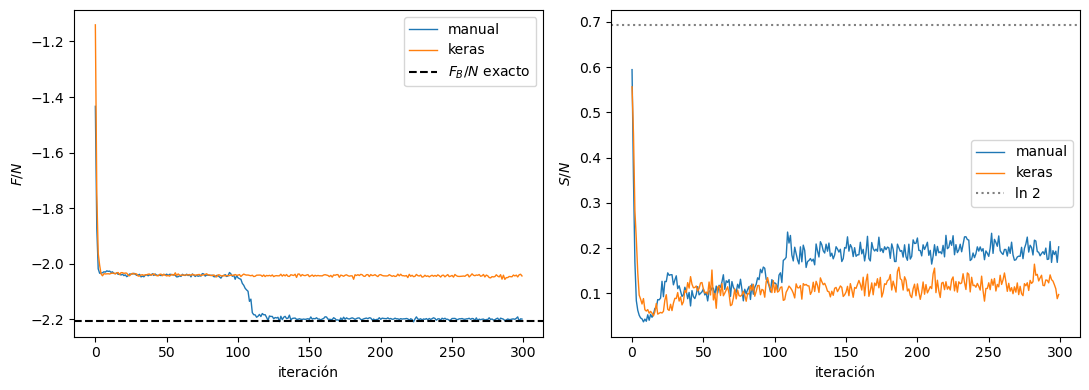

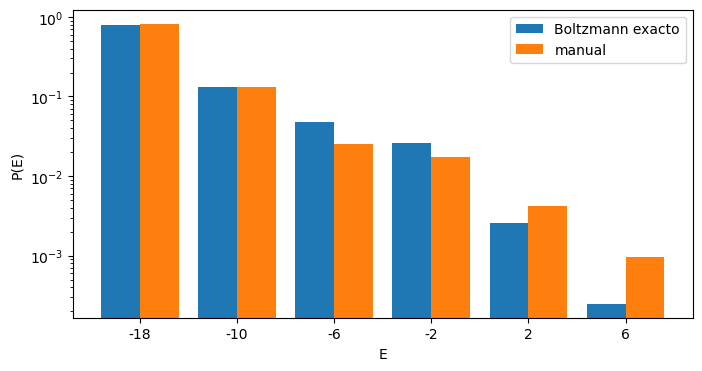

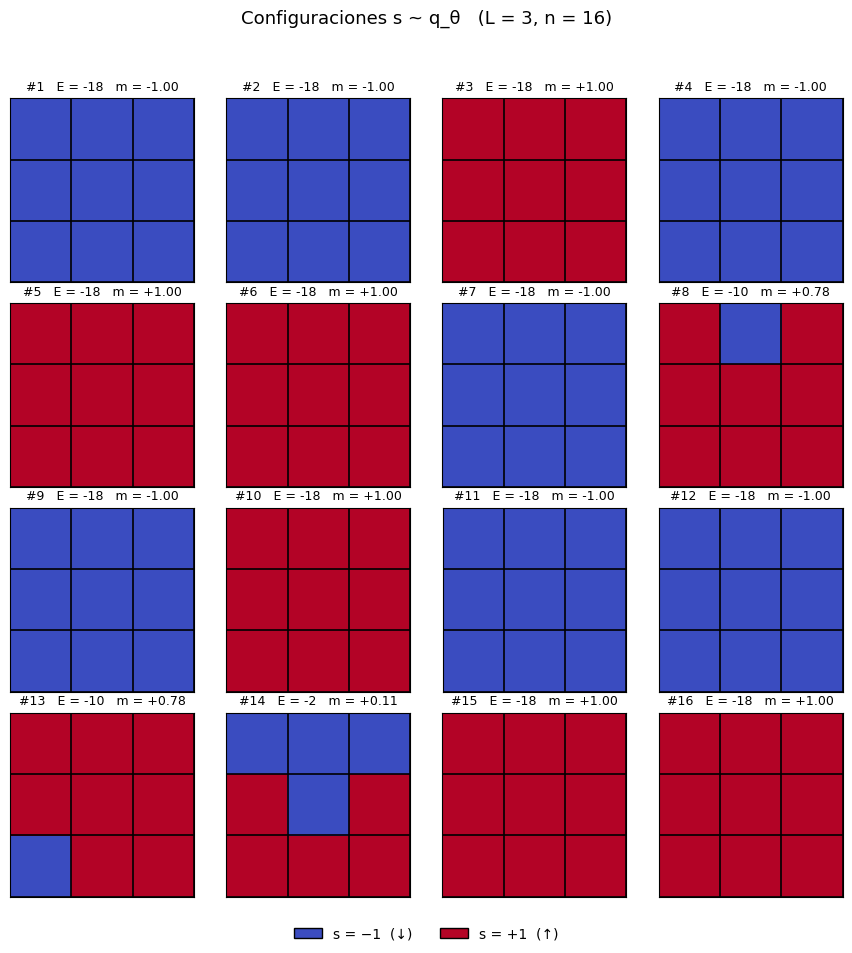

In [16]:
L_out, T_out = 3, 2.0

# 1) Tabla: lote independiente vs Boltzmann exacto
tabla(modelo_manual, L_out, T_out, nombre="manual")
print()
tabla(modelo_keras,  L_out, T_out, nombre="keras")

# 2) Curvas de entrenamiento (ambas implementaciones)
figura_entrenamiento(
    [hist_manual, hist_keras],
    ["manual", "keras"],
    L_out, T_out,
)

# 3) Comparación con enumeración exacta: P(E)
figura_niveles(modelo_manual, L_out, T_out, nombre="manual")

# 4) Ejemplos de configuraciones generadas
figura_muestras(modelo_manual, L_out, n=16, seed=1)

### Análisis del entrenamiento 

| | manual | keras | exacto |
|---|---|---|---|
| $F/N$ | $-2.1997 \pm 0.0004$ | $-2.0423 \pm 0.0004$ | $-2.2056$ |
| $U/N$ | $-1.8106 \pm 0.0044$ | $-1.8275 \pm 0.0039$ | $-1.7677$ |
| $\langle\lvert m\rvert\rangle$ | $0.9457 \pm 0.0014$ | $0.9532 \pm 0.0011$ | $0.9260$ |

Ambos modelos presentan una buena predición. Sin embargo, el modelo manual se estabiliza en un valor de $F/N$ menor y además lo logra en menos iteraciones.


Los dos estados fundamentales de la red (todos con spín up o con spín down),  tienen $p_B \approx 0.397$ y es simétrica respecto a la inversión: $(p_B(s) = p_B(-s))$. El modelo puede aprender solo una de las dos configuraciones, y en este caso 

$$ D_{KL}(q\|p_B) = \ln 2 \quad\Rightarrow\quad \frac{F[q]}{N} = \frac{F_B}{N} + \frac{T \ln 2}{N} = -2.2056 + 0.154 = -2.052 , $$

el cual coincide con el valor en que se estabiliza $F/N$ para el modelo manual y es bastante cercano al resultado exacto.

$S/N$ empieza cerca de $\ln 2$ (a pesos aleatorios $q_\theta$ es casi uniforme), cae a $\sim 0.04$ en las primeras iteraciones (el modelo se concentra casi en una sola configuración) y luego se recupera parcialmente. keras se estabiliza en $\sim 0.11$; el manual salta a $\sim 0.20$ cerca de la iteración 110, cerca del exacto $0.219$. La diferencia entre ambos ($\approx 0.08$) es justamente $\ln 2 / N = 0.077$: un bit de entropía repartido entre los 9 espines. El salto en $S$ coincide en el tiempo con el salto en $F$.

### Distribución por niveles de energía 

- Los dos niveles más probables coinciden muy bien: $E = -18$ (fundamental, $\approx 0.82$ vs $0.79$) y $E = -10$ (un espín invertido, $\approx 0.13$).
- Los niveles intermedios $E = -6$ y $E = -2$ están **subestimados** (en $E=-6$, alrededor de la mitad de lo exacto), y los niveles altos $E = +2$ y $E = +6$ están **sobreestimados** (en $E = +6$, unas 4 veces).
- Los errores relativos crecen donde $P(E)$ es pequeña. La KL inversa pondera cada error por $q(s)$, así que equivocarse en estados de probabilidad $\sim 10^{-3}$ casi no cuesta. Además, esos estados casi nunca aparecen en los lotes de 256 muestras, de modo que el gradiente recibe poca información sobre ellos.
- Esta figura agrega ambos estados fundamentales en la misma barra, así que **no** detectaría el colapso de modo: el modelo keras se vería parecido. Un histograma de $m$ sí lo mostraría.

### Configuraciones generadas

De las 16 muestras del modelo manual, 13 son estados fundamentales ($81\%$, frente a $P_B(E=-18) = 79\%$): 7 con todos los espines $\downarrow$ y 6 con todos $\uparrow$. Hay además dos configuraciones con un espín invertido ($E = -10$) y una con $E = -2$. Que aparezcan ambos signos con frecuencias parecidas muestra que el modelo manual sí aprendió la simetría $\mathbb{Z}_2$, de forma consistente con $q \approx [0.41,\ 0.41]$.

### Manual vs Keras

No parece que una forma de implementar la atención sea mejor que la otra. Las pruebas de causalidad, normalización y muestreo muestran que las dos producen una distribución $q_\theta$ válida con la misma arquitectura. La diferencia más probable está en la inicialización y en la naturaleza estocástica del entrenamiento.